# 41 · Cross-embodiment: one task interface, one expert, three robots (Panda, UR5e + Robotiq, SO-101)

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from vlacourse import TableTop, ScriptedExpert, show_video, show_images

def run(env, seed, frames=None):
    obs = env.reset(seed=seed)
    ex, done, traj = ScriptedExpert(env), False, []
    while not done:
        a = ex.act(obs)
        obs, _, done, info = env.step(a)
        traj.append((obs["state"][:3], obs["qpos"]))
        if frames is not None:
            frames.append(obs["images"]["front"])
    return info["success"], traj

def so101():
    spec = mm.get("robotstudio_so101").spec("scene")
    cube = spec.worldbody.add_body(name="cube", pos=[0.25, 0.0, 0.012]); cube.add_freejoint()
    cube.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.012] * 3, rgba=[0.9, 0.2, 0.2, 1], mass=0.01)
    m = spec.compile(); d = mujoco.MjData(m); mujoco.mj_forward(m, d)
    return m, d

def approach_axis(m, d, site="gripperframe", wrist="wrist"):
    """The SO-101 jaw points along the wrist->gripperframe direction, which is the site's local x axis, not z."""
    sid = m.site(site).id
    a = d.site_xpos[sid] - d.body(wrist).xpos
    return d.site_xmat[sid].reshape(3, 3).T @ (a / np.linalg.norm(a))

def ik_position_down(m, d, target, q0, axis_local, site="gripperframe", n=5, w=0.5, iters=300):
    """5-DoF arm: exact position plus a soft 'jaw points down' term (a 6-D pose is not reachable in general)."""
    q, sid = q0.copy(), m.site(site).id
    jp, jr = np.zeros((3, m.nv)), np.zeros((3, m.nv))
    for _ in range(iters):
        d.qpos[:n] = q; mujoco.mj_kinematics(m, d); mujoco.mj_comPos(m, d)
        a = d.site_xmat[sid].reshape(3, 3) @ axis_local
        e = np.r_[target - d.site_xpos[sid], w * np.cross(a, [0, 0, -1])]
        mujoco.mj_jacSite(m, d, jp, jr, sid)
        J = np.vstack([jp[:, :n], w * jr[:, :n]])
        q = np.clip(q + J.T @ np.linalg.solve(J @ J.T + 1e-3 * np.eye(6), e), m.jnt_range[:n, 0], m.jnt_range[:n, 1])
    return q, np.linalg.norm(target - d.site_xpos[sid]), float(-a[2])

In [2]:
envs = {r: TableTop(robot=r, seed=0, cameras=("front",), image_size=(240, 320)) for r in ["panda", "ur5e"]}
rates = {}
for name, env in envs.items():
    rates[name] = np.mean([run(env, s)[0] for s in range(30)])
    print(f"{name:6s} expert success over 30 episodes: {rates[name]:.0%} | arm DoF = {env.n_arm} | ee site = {env.ee}")

panda  expert success over 30 episodes: 100% | arm DoF = 7 | ee site = ee


ur5e   expert success over 30 episodes: 100% | arm DoF = 6 | ee site = gripper_pinch


{'panda': 60, 'ur5e': 60}
instruction: stack the blue cube on the red cube


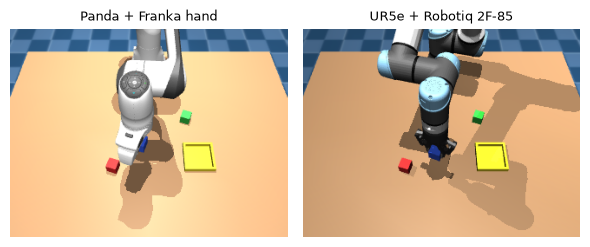

Saved to S04_Classical_Control/outputs


In [3]:
import os
import numpy as np
import imageio
import matplotlib.pyplot as plt

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

frames = {r: [] for r in envs}
for r, env in envs.items():
    run(env, 7, frames[r])
# episodes end at success, and the UR5e takes longer than the Panda: pad the faster robot with its
# final frame (so the video shows BOTH robots finishing) and hold the end for 1 s
n = max(len(f) for f in frames.values()) + 10
for r in frames:
    frames[r] += [frames[r][-1]] * (n - len(frames[r]))
print({r: len(f) for r, f in frames.items()})
print("instruction:", envs["panda"].task["instruction"])

# side-by-side video
video = [np.hstack([frames["panda"][i], frames["ur5e"][i]]) for i in range(n)]
show_video(video, fps=10, title="Panda | UR5e, same expert")
imageio.mimsave(os.path.join(OUT_DIR, "panda_vs_ur5e.mp4"), video, fps=10)  # needs imageio-ffmpeg

# middle-frame images
mid = min(len(f) for f in frames.values()) // 2  # a frame where both robots are mid-task
titles = ["Panda + Franka hand", "UR5e + Robotiq 2F-85"]
imgs = [frames["panda"][mid], frames["ur5e"][mid]]
show_images(imgs, titles)

imageio.imwrite(os.path.join(OUT_DIR, "panda_mid.png"), imgs[0])
imageio.imwrite(os.path.join(OUT_DIR, "ur5e_mid.png"), imgs[1])

# one combined figure with titles
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
fig.savefig(os.path.join(OUT_DIR, "comparison.png"), dpi=150, bbox_inches="tight")
plt.close(fig)

print("Saved to", os.path.abspath(OUT_DIR))

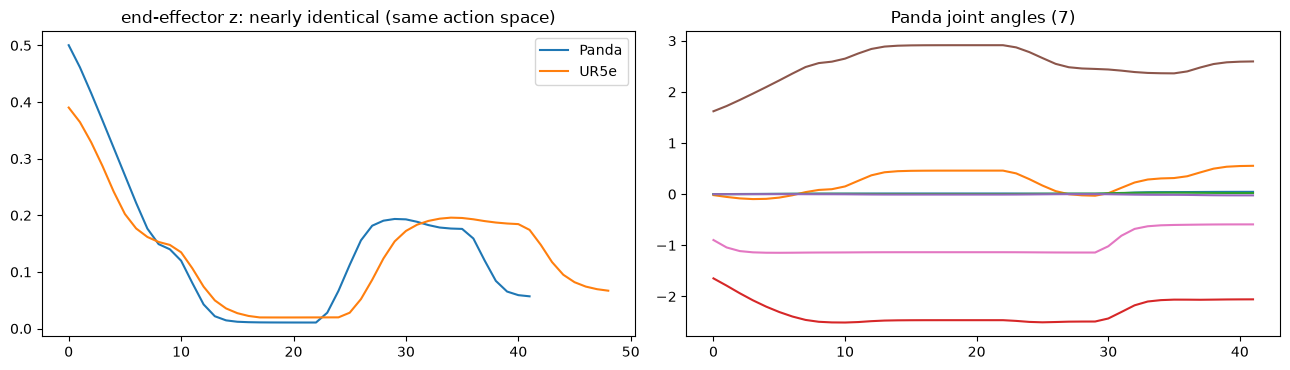

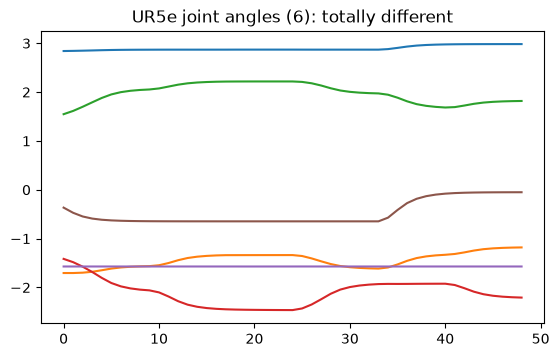

In [4]:
_, tp = run(envs["panda"], 3); _, tu = run(envs["ur5e"], 3)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(np.array([t[0] for t in tp])[:, 2], label="Panda"); ax[0].plot(np.array([t[0] for t in tu])[:, 2], label="UR5e")
ax[0].set_title("end-effector z: nearly identical (same action space)"); ax[0].legend()
ax[1].plot(np.array([t[1] for t in tp])); ax[1].set_title("Panda joint angles (7)")
plt.tight_layout(); plt.show()
plt.figure(figsize=(6.5, 3.8)); plt.plot(np.array([t[1] for t in tu])); plt.title("UR5e joint angles (6): totally different"); plt.show()

In [5]:
m, d = so101()
axis = approach_axis(m, d)
print("jaw direction in the gripperframe site frame:", axis.round(2), "-> the site's x axis, unlike the Panda/UR5e convention (z)")
cube = d.body("cube").xpos.copy()
q = np.zeros(5)
for tgt in [cube + [0, 0, 0.06], cube + [0, 0, 0.005], np.array([0.15, 0.15, 0.05]), np.array([0.32, 0.0, 0.03]), np.array([0.5, 0.0, 0.05])]:
    q, err, down = ik_position_down(m, d, tgt, q, axis)
    print(f"SO-101 target {tgt.round(3)} -> position error {err * 1000:5.1f} mm, jaw·down = {down:.2f}")
print("0.5 m is beyond the SO-101's reach (~0.4 m): TableTop's 30x50 cm workspace must be rescaled for this robot")

jaw direction in the gripperframe site frame: [0.99 0.11 0.07] -> the site's x axis, unlike the Panda/UR5e convention (z)
SO-101 target [0.25  0.    0.072] -> position error  15.8 mm, jaw·down = 0.99
SO-101 target [0.25  0.    0.017] -> position error   0.0 mm, jaw·down = 1.00
SO-101 target [0.15 0.15 0.05] -> position error   0.2 mm, jaw·down = 1.00
SO-101 target [0.32 0.   0.03] -> position error   2.2 mm, jaw·down = 1.00
SO-101 target [0.5  0.   0.05] -> position error 256.6 mm, jaw·down = 0.96
0.5 m is beyond the SO-101's reach (~0.4 m): TableTop's 30x50 cm workspace must be rescaled for this robot


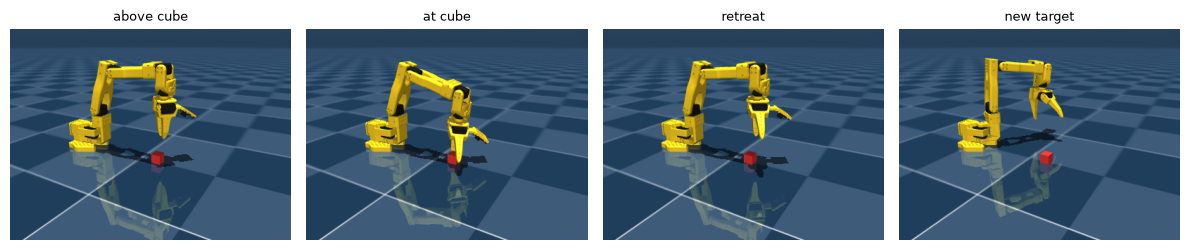

Grasping with the SO-101's rotating jaw needs its own tuning; we do it in capstone C3 (SO-101 sim-to-real).


In [6]:
frames, q = [], np.zeros(5)
with mujoco.Renderer(m, 300, 400) as r:
    for tgt in [cube + [0, 0, 0.06], cube + [0, 0, 0.005], cube + [0, 0, 0.06], np.array([0.15, 0.15, 0.06])]:
        q_goal, _, _ = ik_position_down(m, d, tgt, q, axis)
        for i in range(400):
            s = min(1, (i + 1) / 300)
            d.ctrl[:5] = q + (q_goal - q) * (3 * s * s - 2 * s ** 3); d.ctrl[5] = 1.0
            mujoco.mj_step(m, d)
            if i % 20 == 0:
                cam = mujoco.MjvCamera(); cam.lookat[:] = [0.2, 0.05, 0.05]; cam.distance, cam.azimuth, cam.elevation = 0.7, 120, -20
                r.update_scene(d, cam); frames.append(r.render())
        q = q_goal
show_video(frames, fps=20, title="SO-101 reach")
show_images(frames[::len(frames) // 4][:4], ["above cube", "at cube", "retreat", "new target"])
print("Grasping with the SO-101's rotating jaw needs its own tuning; we do it in capstone C3 (SO-101 sim-to-real).")